# 05 - Planted shortcuts: does R_dir separate *reliance on evidence* from *accuracy*?

**The question a reviewer will ask:** "Isn't R_dir just AUC on another set of images?" So far the two have ranked
models the same way. This notebook creates models where **we know the answer** and checks that R_dir tracks
reliance on the real evidence even when accuracy says the opposite.

### Arm A - image shortcut with known ground truth (DenseNet, Effusion)
- Fine-tune the CheXpert DenseNet (new Effusion head) on NIH patients that are **not** used for testing.
- A synthetic marker (16x16 checkerboard, top-left corner) is stamped on training images: present in a fraction
  **rho** of positives and **1 - rho** of negatives. rho = 0.5 means the marker is useless (= an NIH-trained positive
  control); rho = 1.0 means it predicts the label perfectly.
- On held-out patients we measure:
  - **AUC_iid**: marker still correlated as in training - what a standard benchmark would report;
  - **AUC_clean**: no marker;
  - **R_dir_fixed**: our estimand on the flip pairs with the marker held fixed (off for all 4 images, then on for all 4, averaged);
  - **R_dir_follow**: marker follows the label as in training - shows what happens if the nuisance is *not* held fixed;
  - **marker effect**: P(marker on) - P(marker off) on the same image - the reliance on the shortcut itself.
- **Prediction:** as rho rises, AUC_iid stays high or rises, marker effect rises, and R_dir_fixed falls.
  That is the dissociation the paper needs.

### Arm B - text shortcut in the VLMs (no training)
- Same Effusion anchors as notebook 04 (400 patients). Prompt gets a fake prior report:
  "Prior radiology report: pleural effusion is present." / "... no pleural effusion."
- **R_dir | cue fixed**: image reliance when the same report is shown for all 4 images.
- **Text effect**: P(yes | report present) - P(yes | report absent) on the same image - reliance on the text.
- **R_dir_follow**: the report agrees with each image's label - a "truthful report" makes R_dir look large without any image use.
- Yes/no-mass filter (>= 0.9) is the **primary** analysis (notebook 04 showed low-mass items can create fake reliance).

### Inputs (Add Input)
1. **Dataset:** NIH Chest X-rays (`nih-chest-xrays/data`, Datasets tab) - required.
2. **Notebook output:** your **notebook 04** output - optional, re-uses the no-report (P0) VLM scores (saves ~2 GPU h).
3. **Secret:** `HF_TOKEN` switched on (Add-ons -> Secrets) - needed for MedGemma.
4. **Settings:** Accelerator **GPU T4 x2**, Internet **on**.

**Runtime:** Arm A ~1-1.5 h; Arm B ~2 h with the P0 re-use (Qwen 0.9 s/img, MedGemma 3.8 s/img); ~4 h without.
Use **Save Version -> Save & Run All**. Arm B can be switched off with `RUN_ARM_B = False`.

In [1]:
!pip -q install torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 68.7 MB/s eta 0:00:00


In [2]:
%%writefile pilot_lib.py
# ---- Pair construction and estimation (no model code) ----
import numpy as np
import pandas as pd

NIH_FINDINGS = ["Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Effusion", "Emphysema",
                "Fibrosis", "Hernia", "Infiltration", "Mass", "Nodule", "Pleural_Thickening",
                "Pneumonia", "Pneumothorax"]


def add_label(df, finding):
    out = df.copy()
    out["label"] = out["Finding Labels"].str.split("|").apply(lambda L: int(finding in L))
    return out


def build_anchor_triples(df, finding, same_view=True, max_anchors_per_patient=2, seed=0,
                         match_gap=False, gap_tol=1, control="anchor"):
    """For each anchor image A, find in the SAME patient:
       flip partner  F: another study with the opposite label for `finding` (should change the answer)
       same partner  S: another study with the same label (should not change the answer)
    Partners are the nearest follow-ups (smallest |follow-up gap|) and share A's view if same_view.
    Using a same-patient, different-day image as the control means both arms carry the same kind
    of nuisance change (positioning, exposure, time), so R = S - N subtracts it."""
    rng = np.random.default_rng(seed)
    d = add_label(df, finding)
    key = ["Patient ID", "View Position"] if same_view else ["Patient ID"]
    d = d[d.groupby(key)["Image Index"].transform("size") >= 3]
    rows = []
    for k, g in d.groupby(key):
        pid = k[0] if isinstance(k, tuple) else k
        img = g["Image Index"].to_numpy(); lab = g["label"].to_numpy()
        fu = g["Follow-up #"].to_numpy(); view = g["View Position"].to_numpy()
        if lab.min() == lab.max():
            continue
        anchors = []
        for i in range(len(g)):
            other = np.arange(len(g)) != i
            fl = np.where(other & (lab != lab[i]))[0]
            sm = np.where(other & (lab == lab[i]))[0]
            if len(fl) == 0 or len(sm) == 0:
                continue
            f = fl[np.abs(fu[fl] - fu[i]).argmin()]
            if control == "pair":
                # control = a same-label PAIR (u, v) of this patient with EXACTLY the flip pair's signed
                # follow-up gap; prefer the anchor's status, then the pair closest in time to the anchor
                k = fu[f] - fu[i]
                best = None
                for u in range(len(g)):
                    for v in np.where((fu - fu[u]) == k)[0]:
                        if v == u or lab[u] != lab[v] or {u, v} == {i, f}:
                            continue
                        key_ = (lab[u] != lab[i], abs(fu[u] - fu[i]))
                        if best is None or key_ < best[0]:
                            best = (key_, u, v)
                if best is None:
                    continue
                _, u, v = best
                anchors.append(dict(patient=pid, view=view[i], img_a=img[i], lab_a=int(lab[i]),
                                    img_f=img[f], lab_f=int(lab[f]), img_s1=img[u], img_s=img[v],
                                    lab_s=int(lab[v]), gap_f=int(abs(k)), gap_s=int(abs(fu[v] - fu[u])),
                                    sgap_f=int(k), sgap_s=int(fu[v] - fu[u])))
                continue
            if match_gap:
                # control at the same signed time offset as the flip partner (same direction in time,
                # similar distance), so time/positioning drift is equal in both arms
                off = (fu[sm] - fu[i]) - (fu[f] - fu[i])
                s = sm[np.abs(off).argmin()]
                if abs((fu[s] - fu[i]) - (fu[f] - fu[i])) > gap_tol:
                    continue
            else:
                s = sm[np.abs(fu[sm] - fu[i]).argmin()]
            anchors.append(dict(patient=pid, view=view[i], img_a=img[i], lab_a=int(lab[i]),
                                img_f=img[f], lab_f=int(lab[f]), img_s=img[s], lab_s=int(lab[s]),
                                gap_f=int(abs(fu[f] - fu[i])), gap_s=int(abs(fu[s] - fu[i])),
                                sgap_f=int(fu[f] - fu[i]), sgap_s=int(fu[s] - fu[i])))
        if anchors:
            idx = rng.permutation(len(anchors))[:max_anchors_per_patient]
            rows += [anchors[i] for i in idx]
    if same_view and rows:   # a patient can appear in two view groups: keep the per-patient cap
        t = pd.DataFrame(rows).sample(frac=1, random_state=seed)
        rows = t.groupby("patient").head(max_anchors_per_patient).to_dict("records")
    t = pd.DataFrame(rows)
    if len(t):
        t["direction"] = np.where(t["lab_a"] == 0, "absent->present", "present->absent")
    return t


def flip_counts(df, findings=NIH_FINDINGS, same_view=True):
    """Feasibility table: per finding, patients with a within-patient flip (each direction),
    and anchors with BOTH a flip and a same-label partner."""
    out = []
    key = ["Patient ID", "View Position"] if same_view else ["Patient ID"]
    for f in findings:
        d = add_label(df, f).sort_values(key + ["Follow-up #"])
        diff = d.groupby(key)["label"].diff()
        up = d.loc[diff == 1, "Patient ID"].nunique()      # consecutive studies, same view
        down = d.loc[diff == -1, "Patient ID"].nunique()
        trip = build_anchor_triples(df, f, same_view=same_view, max_anchors_per_patient=1)
        out.append(dict(finding=f, patients_absent_to_present=up, patients_present_to_absent=down,
                        patients_with_flip_and_same_partner=len(trip),
                        of_which_anchor_absent=int((trip["lab_a"] == 0).sum()) if len(trip) else 0,
                        of_which_anchor_present=int((trip["lab_a"] == 1).sum()) if len(trip) else 0))
    return pd.DataFrame(out)


def sample_balanced(trip, n, seed=0):
    """Balance the two flip directions so a yes/no bias cannot masquerade as reliance."""
    parts = [g.sample(min(len(g), n // 2), random_state=seed) for _, g in trip.groupby("direction")]
    return pd.concat(parts).reset_index(drop=True)


def _logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def item_quantities(res, scale="prob"):
    """res needs p_a, p_f, p_s (P(yes) under anchor, flip partner, same-label partner).
    scale='prob' uses probability differences; scale='logit' uses log-odds differences
    (less compressed near 0/1, makes models with different calibration more comparable)."""
    r = res.copy()
    if scale == "logit":
        for c in ["p_a", "p_f", "p_s", "p_s1"]:
            if c in r:
                r[c] = _logit(r[c].to_numpy())
    r["d_change"] = (r["p_f"] - r["p_a"]).abs()          # sensitivity (should be large)
    ref = r["p_s1"] if "p_s1" in r else r["p_a"]          # pair control: |p(C2) - p(C1)|
    r["d_preserve"] = (r["p_s"] - ref).abs()             # nuisance sensitivity (should be small)
    r["R"] = r["d_change"] - r["d_preserve"]             # evidence-specific reliance
    dy = r["lab_f"] - r["lab_a"]                          # +1 absent->present, -1 present->absent
    r["signed_dir"] = (r["p_f"] - r["p_a"]) * dy          # >0 = moved the right way
    # Directional, time-matched estimand (primary): change toward the new label on the flip pair,
    # minus the same signed change on a same-label pair of the same patient at the same time offset
    r["D_flip"] = r["signed_dir"]
    r["D_ctrl"] = (r["p_s"] - ref) * dy
    r["R_dir"] = r["D_flip"] - r["D_ctrl"]
    # Sign version: only the DIRECTION of movement counts, so any monotone recalibration of the
    # model's scores (saturation, temperature) leaves it unchanged. Ties count 0.
    r["S_flip"] = np.sign(r["p_f"] - r["p_a"]) * dy
    r["S_ctrl"] = np.sign(r["p_s"] - ref) * dy
    r["R_sign"] = r["S_flip"] - r["S_ctrl"]
    return r


DEFAULT_COLS = ("D_flip", "D_ctrl", "R_dir", "S_flip", "S_ctrl", "R_sign", "d_change", "d_preserve", "R")


def cluster_bootstrap(r, cols=DEFAULT_COLS, B=2000, seed=0, by="patient"):
    """Point estimates (mean of patient means) and percentile CIs resampling PATIENTS."""
    rng = np.random.default_rng(seed)
    cols = [c for c in cols if c in r]
    pm = r.groupby(by)[cols].mean()
    est = pm.mean()
    boots = np.empty((B, len(cols)))
    n = len(pm)
    arr = pm.to_numpy()
    for b in range(B):
        boots[b] = arr[rng.integers(0, n, n)].mean(axis=0)
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    p_le0 = (boots <= 0).mean(axis=0)               # one-sided bootstrap p for H0: quantity <= 0
    return pd.DataFrame({"estimate": est.values, "ci_low": lo, "ci_high": hi, "p_one_sided": p_le0,
                         "n_patients": n}, index=cols)


def summarize(r, B=2000, seed=0):
    from scipy.stats import binomtest
    overall = cluster_bootstrap(r, B=B, seed=seed)
    by_dir = {k: cluster_bootstrap(g, B=B, seed=seed) for k, g in r.groupby("direction")}
    pm = r.groupby("patient")["R_dir" if "R_dir" in r else "R"].mean()
    nz = pm[pm != 0]
    sign_p = binomtest(int((nz > 0).sum()), len(nz), 0.5, alternative="greater").pvalue if len(nz) else np.nan
    acc = ((r["p_a"] > 0.5).astype(int) == r["lab_a"]).mean()
    return overall, by_dir, sign_p, acc


def paired_difference(r1, r2, col="R", B=4000, seed=0):
    """Difference in a per-item quantity between two models scored on the SAME anchors,
    with a patient-level paired bootstrap. Returns estimate, CI and two-sided bootstrap p."""
    rng = np.random.default_rng(seed)
    a = r1.groupby("patient")[col].mean(); b = r2.groupby("patient")[col].mean()
    a, b = a.align(b, join="inner")
    d = (a - b).to_numpy(); n = len(d)
    boots = np.array([d[rng.integers(0, n, n)].mean() for _ in range(B)])
    p = 2 * min((boots <= 0).mean(), (boots >= 0).mean())
    return dict(estimate=d.mean(), ci_low=np.percentile(boots, 2.5), ci_high=np.percentile(boots, 97.5),
                p_boot=min(p, 1.0), n_patients=n)


def gap_balance(t):
    """Check that the control is time-matched to the flip partner."""
    return pd.Series({"mean_gap_flip": t["gap_f"].mean(), "mean_gap_same": t["gap_s"].mean(),
                      "share_same_time_direction": (np.sign(t["sgap_f"]) == np.sign(t["sgap_s"])).mean()
                      if "sgap_f" in t else np.nan})


Writing pilot_lib.py


In [3]:
%%writefile prep_lib.py
# image loading for worker processes (must live in a module so multiprocessing can import it)
import numpy as np, skimage.io, torchvision, torchxrayvision as xrv
_tfm = torchvision.transforms.Compose([xrv.datasets.XRayCenterCrop(), xrv.datasets.XRayResizer(224)])

def prep(path):
    """Same preprocessing as notebooks 02-04, stored as uint8 224x224 to save memory."""
    img = skimage.io.imread(path)
    if img.ndim == 3:
        img = img[..., :3].mean(2)
    x = _tfm(xrv.utils.normalize(img, 255 if img.max() <= 255 else 65535)[None])[0]
    return np.clip((x / 1024 + 1) / 2 * 255, 0, 255).astype(np.uint8)

Writing prep_lib.py


In [4]:
import os, glob, json, time, gc, copy, shutil, traceback
import numpy as np, pandas as pd
from pilot_lib import *
T0 = time.time()

FINDING = "Effusion"
SEED = 0
OUT = "/kaggle/working"
COLS = ["img_a", "img_f", "img_s1", "img_s"]
# --- Arm A ---
RHOS = [0.5, 0.7, 0.9, 1.0]
TRAIN_SEEDS = [0, 1]
N_TRAIN_PER_CLASS = 4000     # training images per class (max 3 per patient)
N_VAL_PER_CLASS = 500
N_RANDOM = 1000              # held-out random test images (half positive), one per patient
EPOCHS, BATCH, LR_BACKBONE, LR_HEAD = 4, 64, 5e-5, 1e-3
# --- Arm B ---
RUN_ARM_B = True
N_VLM = 400
MASS_MIN = 0.9
QUESTION = "Is there a pleural effusion in this chest X-ray? Answer yes or no."
CUES = {"none": None,   # = prompt P0 of notebook 04
        "pos": "Prior radiology report: pleural effusion is present.",
        "neg": "Prior radiology report: no pleural effusion."}
VLMS = [("Qwen/Qwen2.5-VL-7B-Instruct", "float16"), ("google/medgemma-4b-it", "float32")]
MAX_PIXELS = 512 * 28 * 28
TIME_BUDGET_H = 11.0
def out_of_time():
    return (time.time() - T0) / 3600 > TIME_BUDGET_H

## 1. NIH metadata and images

In [5]:
def find_file(name, top="/kaggle/input"):
    for r, dirs, files in os.walk(top, followlinks=True):
        if name in files:
            return os.path.join(r, name)
        dirs[:] = [d for d in dirs if not d.startswith("images")]
    return None

print("Attached inputs:", os.listdir("/kaggle/input"))
meta = find_file("Data_Entry_2017.csv") or find_file("Data_Entry_2017_v2020.csv")
assert meta, "Attach the NIH Chest X-rays dataset (Add Input -> Datasets -> nih-chest-xrays/data)"
df = pd.read_csv(meta); df.columns = [c.strip() for c in df.columns]
root = os.path.dirname(meta)
img_paths = {os.path.basename(p): p for p in glob.glob(f"{root}/**/*.png", recursive=True)}
print(df.shape, "|", len(img_paths), "images")
assert img_paths, "Images not found - the dataset must be attached, not only the CSV"

Attached inputs: ['datasets']
(112120, 12) | 112120 images


## 2. Patient splits
Test patients = the Effusion anchor patients (same construction as notebooks 03/04) + 1,000 random held-out patients.
Training/validation use **only the remaining patients**, so no test patient is ever seen in training.

In [6]:
trip = build_anchor_triples(df, FINDING, same_view=True, max_anchors_per_patient=1, seed=SEED, control="pair")
trip = trip[trip[COLS].isin(list(img_paths)).all(axis=1)]
samp = sample_balanced(trip, 1500, seed=SEED).reset_index(drop=True)
v800 = sample_balanced(samp.assign(_i=samp.index), 800, seed=SEED + 1)               # as notebook 03
samp["vlm"] = samp.index.isin(sample_balanced(v800, N_VLM, seed=SEED + 2)["_i"])     # as notebook 04
print("anchors:", len(samp), samp["direction"].value_counts().to_dict(), "| VLM anchors:", int(samp["vlm"].sum()))

lab = add_label(df, FINDING)
lab = lab[lab["Image Index"].isin(list(img_paths))]
rest = lab[~lab["Patient ID"].isin(samp["patient"])]
one = rest.sample(frac=1, random_state=SEED).drop_duplicates("Patient ID")            # as notebook 03
rand = pd.concat([one[one["label"] == 1].head(N_RANDOM // 2), one[one["label"] == 0].head(N_RANDOM // 2)])

pool = rest[~rest["Patient ID"].isin(rand["Patient ID"])]
pats = pool["Patient ID"].unique(); rng = np.random.default_rng(SEED); rng.shuffle(pats)
val_p = set(pats[: len(pats) // 10])
def pick(d, n):
    d = d.sample(frac=1, random_state=SEED).groupby("Patient ID").head(3)
    return pd.concat([d[d["label"] == 1].head(n), d[d["label"] == 0].head(n)])
train = pick(pool[~pool["Patient ID"].isin(val_p)], N_TRAIN_PER_CLASS)
val = pick(pool[pool["Patient ID"].isin(val_p)], N_VAL_PER_CLASS)
test_pat = set(samp["patient"]) | set(rand["Patient ID"])
assert not (set(train["Patient ID"]) | set(val["Patient ID"])) & test_pat, "patient leakage"
print("train", train["label"].value_counts().to_dict(), "| val", val["label"].value_counts().to_dict(),
      "| random test", rand["label"].value_counts().to_dict())
samp.to_csv(f"{OUT}/triples05.csv", index=False)

anchors: 1445 {'absent->present': 750, 'present->absent': 695} | VLM anchors: 400
train {0: 4000, 1: 1732} | val {0: 500, 1: 193} | random test {1: 500, 0: 500}


## 3. Preprocess all needed images once (uint8, 224 x 224, kept in RAM)

In [7]:
from multiprocessing import Pool
from prep_lib import prep
need = sorted(set(train["Image Index"]) | set(val["Image Index"]) | set(rand["Image Index"])
              | set(samp[COLS].to_numpy().ravel()))
t = time.time()
with Pool(os.cpu_count()) as pool_:
    arrs = pool_.map(prep, [img_paths[k] for k in need], chunksize=32)
U8 = np.stack(arrs); IDX = {k: i for i, k in enumerate(need)}; del arrs
print(U8.shape, f"{U8.nbytes / 1e9:.2f} GB, {time.time() - t:.0f}s")

(12578, 224, 224) 0.63 GB, 272s


## 4. Arm A - marker, model, training

In [8]:
import torch, torch.nn as nn, torch.nn.functional as F, torchxrayvision as xrv
from sklearn.metrics import roc_auc_score
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev, "| GPUs:", torch.cuda.device_count())

CHECK = (np.indices((16, 16)).sum(0) // 4 % 2 * 255).astype(np.uint8)   # 4-px checkerboard, 16x16
def with_marker(x, on):
    x = x.copy(); x[on, 6:22, 6:22] = CHECK; return x

def to_t(x):
    return torch.from_numpy(x).float().div_(255).mul_(2048).sub_(1024)[:, None].to(dev)

base = xrv.models.DenseNet(weights="densenet121-res224-chex").eval()
EFF = base.targets.index(FINDING)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = copy.deepcopy(base.features)
        self.head = nn.Linear(1024, 1)          # new head: starts with no preference for either cue
    def forward(self, x):
        f = F.adaptive_avg_pool2d(F.relu(self.features(x)), 1).flatten(1)
        return self.head(f).squeeze(1)

@torch.no_grad()
def predict(net, keys, on):
    """P(effusion) for image keys; on = bool array, marker stamped where True."""
    net.eval(); out = []
    x = U8[[IDX[k] for k in keys]]
    for i in range(0, len(keys), 128):
        xb = to_t(with_marker(x[i:i + 128], on[i:i + 128]))
        with torch.autocast(dev, dtype=torch.float16, enabled=dev == "cuda"):
            out.append(torch.sigmoid(net(xb).float()).cpu().numpy())
    return np.concatenate(out)

def marker_draw(y, rho, seed):
    """marker on with prob rho for positives and 1 - rho for negatives"""
    r = np.random.default_rng(seed).random(len(y))
    return np.where(y == 1, r < rho, r < 1 - rho)

def train_model(rho, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    net = Net().to(dev)
    ytr = train["label"].to_numpy(); mtr = marker_draw(ytr, rho, 1000 + seed)    # fixed per image, like a dataset artefact
    xtr = U8[[IDX[k] for k in train["Image Index"]]]
    opt = torch.optim.AdamW([{"params": net.features.parameters(), "lr": LR_BACKBONE},
                             {"params": net.head.parameters(), "lr": LR_HEAD}], weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler(enabled=dev == "cuda")
    for ep in range(EPOCHS):
        net.train(); perm = np.random.default_rng(seed * 100 + ep).permutation(len(ytr)); tl = []
        for i in range(0, len(perm), BATCH):
            b = perm[i:i + BATCH]
            xb = to_t(with_marker(xtr[b], mtr[b])); yb = torch.tensor(ytr[b], dtype=torch.float32, device=dev)
            with torch.autocast(dev, dtype=torch.float16, enabled=dev == "cuda"):
                loss = F.binary_cross_entropy_with_logits(net(xb).float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl.append(loss.item())
        yv = val["label"].to_numpy()
        pv = predict(net, list(val["Image Index"]), marker_draw(yv, rho, 2000 + seed))
        print(f"  rho={rho} seed={seed} epoch {ep + 1}: train loss {np.mean(tl):.3f} | val AUC (marker as in training) {roc_auc_score(yv, pv):.3f}")
    return net

device: cuda | GPUs: 2
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/chex-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]


## 5. Arm A - evaluation

In [9]:
ROLES = {"a": "img_a", "f": "img_f", "s1": "img_s1", "s": "img_s"}
anchor_keys = sorted(set(samp[COLS].to_numpy().ravel()))
lab_img = lab.set_index("Image Index")["label"]

def anchor_items(p_of):
    """p_of: dict image -> P(effusion). Returns per-anchor quantities (pilot_lib.item_quantities)."""
    s = samp.copy()
    for c, col in ROLES.items():
        s[f"p_{c}"] = s[col].map(p_of)
    return item_quantities(s, scale="prob")

def evaluate(score_fn, name):
    """score_fn(keys, on) -> probs. Returns one row of the results table plus the item tables."""
    k = anchor_keys
    p_off = dict(zip(k, score_fn(k, np.zeros(len(k), bool))))
    p_on = dict(zip(k, score_fn(k, np.ones(len(k), bool))))
    r_off, r_on = anchor_items(p_off), anchor_items(p_on)
    r_fix = r_off.copy()
    for q in ["D_flip", "D_ctrl", "R_dir", "S_flip", "S_ctrl", "R_sign"]:
        r_fix[q] = (r_off[q] + r_on[q]) / 2
    # marker follows label as in training (rho of this model; 0.5 for the pretrained reference)
    rho = name.get("rho", 0.5) if isinstance(name.get("rho"), float) else 0.5
    m_follow = dict(zip(k, marker_draw(lab_img.loc[k].to_numpy(), rho, 3000)))
    r_fol = anchor_items({x: (p_on if m_follow[x] else p_off)[x] for x in k})
    # marker effect on the same image (patient-clustered)
    me = pd.DataFrame({"patient": samp["patient"].to_numpy(),
                       "m": [np.mean([p_on[samp.at[i, c]] - p_off[samp.at[i, c]] for c in COLS]) for i in samp.index],
                       "m_sign": [np.mean([np.sign(p_on[samp.at[i, c]] - p_off[samp.at[i, c]]) for c in COLS]) for i in samp.index]})
    # AUCs on held-out random patients
    rk = list(rand["Image Index"]); ry = rand["label"].to_numpy()
    auc = lambda on: roc_auc_score(ry, score_fn(rk, on))
    row = dict(**name, AUC_clean=auc(np.zeros(len(rk), bool)), AUC_iid=auc(marker_draw(ry, rho, 4000)),
               AUC_anti=auc(marker_draw(ry, 1 - rho, 4000)))
    b = cluster_bootstrap(r_fix, cols=["R_dir", "R_sign", "D_ctrl"], B=2000, seed=SEED)
    for q in ["R_dir", "R_sign"]:
        row[q + "_fixed"] = b.loc[q, "estimate"]; row[q + "_fixed_lo"] = b.loc[q, "ci_low"]; row[q + "_fixed_hi"] = b.loc[q, "ci_high"]
    row["R_dir_off"] = r_off["R_dir"].mean(); row["R_dir_on"] = r_on["R_dir"].mean()
    bf = cluster_bootstrap(r_fol, cols=["R_dir"], B=2000, seed=SEED)
    row["R_dir_follow"] = bf.loc["R_dir", "estimate"]; row["R_dir_follow_lo"] = bf.loc["R_dir", "ci_low"]; row["R_dir_follow_hi"] = bf.loc["R_dir", "ci_high"]
    bm = cluster_bootstrap(me, cols=["m", "m_sign"], B=2000, seed=SEED)
    row["marker_effect"] = bm.loc["m", "estimate"]; row["marker_effect_lo"] = bm.loc["m", "ci_low"]; row["marker_effect_hi"] = bm.loc["m", "ci_high"]
    row["marker_sign"] = bm.loc["m_sign", "estimate"]
    return row, r_fix

# reference: the pretrained CheXpert DenseNet (never saw the marker; should show marker effect ~ 0)
base = base.to(dev)
@torch.no_grad()
def base_score(keys, on):
    x = U8[[IDX[k] for k in keys]]; out = []
    for i in range(0, len(keys), 128):
        out.append(base(to_t(with_marker(x[i:i + 128], on[i:i + 128])))[:, EFF].float().cpu().numpy())
    return np.concatenate(out)
rows = []
row, _ = evaluate(base_score, dict(model="pretrained CheXpert", rho="-", seed="-")); rows.append(row)
print(pd.DataFrame(rows).round(3).to_string())

for rho in RHOS:
    for sd in TRAIN_SEEDS:
        if out_of_time():
            print("time budget reached"); break
        t = time.time(); net = train_model(rho, sd)
        row, r_fix = evaluate(lambda k, on: predict(net, k, on), dict(model="fine-tuned", rho=rho, seed=sd))
        row["train_min"] = (time.time() - t) / 60; rows.append(row)
        r_fix.to_csv(f"{OUT}/items05_armA_rho{rho}_seed{sd}.csv", index=False)
        print(pd.DataFrame([row]).round(3).to_string())
        del net; gc.collect(); torch.cuda.empty_cache()
armA = pd.DataFrame(rows); armA.to_csv(f"{OUT}/armA05.csv", index=False)
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 40)
display(armA.round(3))

                 model rho seed  AUC_clean  AUC_iid  AUC_anti  R_dir_fixed  R_dir_fixed_lo  R_dir_fixed_hi  R_sign_fixed  R_sign_fixed_lo  R_sign_fixed_hi  R_dir_off  R_dir_on  R_dir_follow  R_dir_follow_lo  R_dir_follow_hi  marker_effect  marker_effect_lo  marker_effect_hi  marker_sign
0  pretrained CheXpert   -    -      0.769    0.768     0.768        0.062           0.042           0.082         0.176            0.099            0.251      0.063     0.062         0.062            0.041            0.081          0.012             0.011             0.012        0.912
  rho=0.5 seed=0 epoch 1: train loss 0.530 | val AUC (marker as in training) 0.800
  rho=0.5 seed=0 epoch 2: train loss 0.465 | val AUC (marker as in training) 0.805
  rho=0.5 seed=0 epoch 3: train loss 0.454 | val AUC (marker as in training) 0.811
  rho=0.5 seed=0 epoch 4: train loss 0.443 | val AUC (marker as in training) 0.814
        model  rho  seed  AUC_clean  AUC_iid  AUC_anti  R_dir_fixed  R_dir_fixed_lo  R_dir_f

,model,rho,seed,AUC_clean,AUC_iid,AUC_anti,R_dir_fixed,R_dir_fixed_lo,R_dir_fixed_hi,R_sign_fixed,R_sign_fixed_lo,R_sign_fixed_hi,R_dir_off,R_dir_on,R_dir_follow,R_dir_follow_lo,R_dir_follow_hi,marker_effect,marker_effect_lo,marker_effect_hi,marker_sign,train_min
0,pretrained CheXpert,-,-,0.769,0.768,0.768,0.062,0.042,0.082,0.176,0.099,0.251,0.063,0.062,0.062,0.041,0.081,0.012,0.011,0.012,0.912,NaN
1,fine-tuned,0.5,0,0.819,0.818,0.818,0.077,0.058,0.095,0.207,0.134,0.280,0.076,0.077,0.076,0.058,0.095,0.005,0.005,0.006,0.728,2.205
2,fine-tuned,0.5,1,0.820,0.820,0.820,0.075,0.057,0.094,0.196,0.125,0.273,0.075,0.075,0.075,0.057,0.093,0.006,0.006,0.006,0.720,2.183
3,fine-tuned,0.7,0,0.812,0.845,0.748,0.074,0.056,0.093,0.181,0.112,0.255,0.073,0.076,0.138,0.118,0.158,0.159,0.157,0.162,1.000,2.190
4,fine-tuned,0.7,1,0.815,0.848,0.749,0.073,0.055,0.091,0.158,0.089,0.231,0.070,0.076,0.139,0.119,0.159,0.165,0.163,0.168,1.000,2.191
5,fine-tuned,0.9,0,0.784,0.946,0.232,0.044,0.031,0.057,0.165,0.095,0.236,0.041,0.048,0.524,0.497,0.549,0.601,0.595,0.607,1.000,2.187
6,fine-tuned,0.9,1,0.789,0.946,0.229,0.043,0.029,0.055,0.160,0.089,0.227,0.039,0.046,0.532,0.505,0.558,0.613,0.607,0.620,1.000,2.186
7,fine-tuned,1.0,0,0.698,1.000,0.000,-0.000,-0.004,0.004,0.108,0.044,0.169,-0.004,0.003,0.947,0.941,0.953,0.946,0.944,0.949,1.000,2.183
8,fine-tuned,1.0,1,0.694,1.000,0.000,0.001,-0.003,0.004,0.107,0.044,0.167,-0.002,0.003,0.952,0.947,0.956,0.950,0.948,0.952,1.000,2.189


AUC_iid        AUC_clean        AUC_anti        R_dir_fixed        R_sign_fixed        R_dir_follow        marker_effect       
       mean    std      mean    std     mean    std        mean    std         mean    std         mean    std          mean    std
rho                                                                                                                                
0.5   0.819  0.001     0.819  0.001    0.819  0.001       0.076  0.001        0.201  0.008        0.076  0.001         0.006  0.000
0.7   0.847  0.002     0.814  0.002    0.749  0.000       0.074  0.001        0.170  0.016        0.138  0.001         0.162  0.004
0.9   0.946  0.000     0.787  0.003    0.231  0.002       0.043  0.001        0.163  0.004        0.528  0.006         0.607  0.009
1.0   1.000  0.000     0.696  0.003    0.000  0.000       0.000  0.001        0.107  0.001        0.949  0.003         0.948  0.003

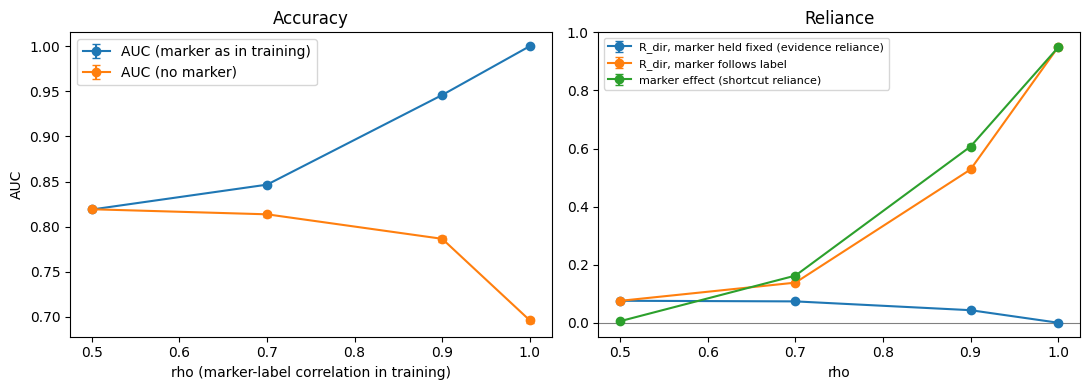

In [10]:
# Arm A summary over seeds and the key figure
import matplotlib.pyplot as plt
ft = armA[armA["model"] == "fine-tuned"].copy(); ft["rho"] = ft["rho"].astype(float)
agg = ft.groupby("rho")[["AUC_iid", "AUC_clean", "AUC_anti", "R_dir_fixed", "R_sign_fixed", "R_dir_follow", "marker_effect"]].agg(["mean", "std"])
display(agg.round(3)); agg.to_csv(f"{OUT}/armA05_by_rho.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for q, lbl in [("AUC_iid", "AUC (marker as in training)"), ("AUC_clean", "AUC (no marker)")]:
    ax[0].errorbar(agg.index, agg[(q, "mean")], yerr=agg[(q, "std")], marker="o", label=lbl, capsize=3)
ax[0].set_xlabel("rho (marker-label correlation in training)"); ax[0].set_ylabel("AUC"); ax[0].legend(); ax[0].set_title("Accuracy")
for q, lbl in [("R_dir_fixed", "R_dir, marker held fixed (evidence reliance)"), ("R_dir_follow", "R_dir, marker follows label"),
               ("marker_effect", "marker effect (shortcut reliance)")]:
    ax[1].errorbar(agg.index, agg[(q, "mean")], yerr=agg[(q, "std")], marker="o", label=lbl, capsize=3)
ax[1].axhline(0, color="grey", lw=0.8); ax[1].set_xlabel("rho"); ax[1].legend(fontsize=8); ax[1].set_title("Reliance")
plt.tight_layout(); plt.savefig(f"{OUT}/armA05.png", dpi=110); plt.show()
del U8, base; gc.collect(); torch.cuda.empty_cache()   # free RAM/GPU before the VLMs

## 6. Arm B - VLMs with a fake prior report

In [11]:
if RUN_ARM_B:
    from PIL import Image
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        print("No HF_TOKEN secret - MedGemma will be skipped")

    def make_vlm(name, dtype):
        from transformers import AutoProcessor
        try:
            from transformers import AutoModelForImageTextToText as Auto
        except ImportError:
            from transformers import AutoModelForVision2Seq as Auto
        dt = getattr(torch, dtype)
        extra = {"attn_implementation": "eager"} if "gemma" in name.lower() else {}
        m = Auto.from_pretrained(name, torch_dtype=dt, device_map="auto", token=token, **extra).eval()
        kw = {"max_pixels": MAX_PIXELS} if "Qwen" in name else {}
        proc = AutoProcessor.from_pretrained(name, token=token, **kw)
        tok = proc.tokenizer
        ids = lambda ws: sorted({tok.encode(w, add_special_tokens=False)[0] for w in ws})
        YES, NO = ids(["Yes", "yes", " Yes", " yes"]), ids(["No", "no", " No", " no"])
        mdev = next(m.parameters()).device
        def inputs(img, question):
            msgs = [{"role": "user", "content": [{"type": "image", "image": img}, {"type": "text", "text": question}]}]
            try:
                inp = proc.apply_chat_template(msgs, add_generation_prompt=True, tokenize=True, return_dict=True, return_tensors="pt")
            except Exception:
                msgs[0]["content"][0] = {"type": "image"}
                text = proc.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
                inp = proc(text=[text], images=[img], return_tensors="pt")
            out = {}
            for k, v in inp.items():
                if torch.is_tensor(v):
                    v = v.to(mdev)
                    if v.is_floating_point():
                        v = v.to(dt)
                out[k] = v
            return out
        @torch.no_grad()
        def score(path, question):
            img = Image.open(path).convert("RGB")
            lp = torch.log_softmax(m(**inputs(img, question)).logits[0, -1].float(), -1)
            ly, ln = torch.logsumexp(lp[YES], 0), torch.logsumexp(lp[NO], 0)
            return torch.sigmoid(ly - ln).item(), (ly.exp() + ln.exp()).item()
        return score, m

    def cache_path(tag, cue):
        return f"{OUT}/scores05_{FINDING}_{tag}_{cue}.json"
    load = lambda p: json.load(open(p)) if os.path.exists(p) else {}

    # re-use notebook 04 P0 scores (identical prompt) as the 'none' condition
    for r, dirs, files in os.walk("/kaggle/input", followlinks=True):
        dirs[:] = [d for d in dirs if not d.startswith("images")]
        for f in files:
            if (f.startswith("scores04_Effusion_") and f.endswith("_P0.json")) or (f.startswith("scores05_") and f.endswith(".json")):
                tag = f[len("scores04_Effusion_"):-len("_P0.json")] if f.startswith("scores04") else None
                dst = cache_path(tag, "none") if tag else f"{OUT}/{f}"
                c = load(dst); c.update(json.load(open(os.path.join(r, f)))); json.dump(c, open(dst, "w"))
                print("re-used", f, "->", os.path.basename(dst))

    vsamp = samp[samp["vlm"]]
    vimgs = list(pd.unique(vsamp[COLS].to_numpy().ravel()))
    timing = []
    for name, dtype in VLMS:
        tag = name.split("/")[-1]
        if "medgemma" in name and token is None:
            print("skip", name, "(switch on the HF_TOKEN secret)"); continue
        pending = [c for c in CUES if set(vimgs) - set(load(cache_path(tag, c)))]
        if not pending or out_of_time():
            print(tag, "nothing to do" if not pending else "out of time"); continue
        model = None
        try:
            score, model = make_vlm(name, dtype)
            for cue in pending:
                q = QUESTION if CUES[cue] is None else CUES[cue] + "\n" + QUESTION
                cp = cache_path(tag, cue); c = load(cp); todo = [k for k in vimgs if k not in c]
                print(f"{tag} | cue={cue} | {len(todo)} images | {q!r}"); t = time.time()
                for i, k in enumerate(todo):
                    if out_of_time():
                        print("  time budget reached"); break
                    c[k] = score(img_paths[k], q)
                    if i % 200 == 0:
                        json.dump(c, open(cp, "w")); print(f"  {i}/{len(todo)} {time.time() - t:.0f}s")
                json.dump(c, open(cp, "w"))
                timing.append(dict(model=tag, cue=cue, n=len(todo), sec_per_img=(time.time() - t) / max(len(todo), 1)))
        except Exception:
            print("FAILED", name); traceback.print_exc()
        finally:
            del model; gc.collect(); torch.cuda.empty_cache()
    print(pd.DataFrame(timing))

re-used scores04_Effusion_medgemma-4b-it_P0.json -> scores05_Effusion_medgemma-4b-it_none.json
re-used scores04_Effusion_Qwen2.5-VL-7B-Instruct_P0.json -> scores05_Effusion_Qwen2.5-VL-7B-Instruct_none.json
re-used scores05_Effusion_Qwen2.5-VL-7B-Instruct_neg.json -> scores05_Effusion_Qwen2.5-VL-7B-Instruct_neg.json
re-used scores05_Effusion_Qwen2.5-VL-7B-Instruct_pos.json -> scores05_Effusion_Qwen2.5-VL-7B-Instruct_pos.json
re-used scores05_Effusion_Qwen2.5-VL-7B-Instruct_none.json -> scores05_Effusion_Qwen2.5-VL-7B-Instruct_none.json
re-used scores05_Effusion_medgemma-4b-it_none.json -> scores05_Effusion_medgemma-4b-it_none.json
Qwen2.5-VL-7B-Instruct nothing to do


config.json:   0%|          | 0.00/2.47k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

medgemma-4b-it | cue=pos | 1428 images | 'Prior radiology report: pleural effusion is present.\nIs there a pleural effusion in this chest X-ray? Answer yes or no.'
  0/1428 4s
  200/1428 699s
  400/1428 1396s
  600/1428 2093s
  800/1428 2789s
  1000/1428 3486s
  1200/1428 4182s
  1400/1428 4879s
medgemma-4b-it | cue=neg | 1428 images | 'Prior radiology report: no pleural effusion.\nIs there a pleural effusion in this chest X-ray? Answer yes or no.'
  0/1428 3s
  200/1428 699s
  400/1428 1395s
  600/1428 2090s
  800/1428 2785s
  1000/1428 3480s
  1200/1428 4175s
  1400/1428 4870s
            model  cue     n  sec_per_img
0  medgemma-4b-it  pos  1428     3.482513
1  medgemma-4b-it  neg  1428     3.476174


In [12]:
if RUN_ARM_B:
    def vitems(sc, cue_of, mass_min):
        """cue_of(image) -> which cue's score to use for that image. Drops anchors with low yes/no mass."""
        s = vsamp.copy()
        for c, col in ROLES.items():
            v = s[col].map(lambda k: sc[cue_of(k)].get(k, (np.nan, 0.0)))
            s[f"p_{c}"] = v.map(lambda t: t[0]); s[f"m_{c}"] = v.map(lambda t: t[1])
        s = s.dropna(subset=[f"p_{c}" for c in ROLES])
        if mass_min:
            s = s[s[[f"m_{c}" for c in ROLES]].min(axis=1) >= mass_min]
        return item_quantities(s, scale="prob")

    rowsB, RB = [], {}
    for name, _ in VLMS:
        tag = name.split("/")[-1]
        sc = {c: load(cache_path(tag, c)) for c in CUES}
        if not all(len(v) for v in sc.values()):
            print(tag, "missing scores for some cue - skipped"); continue
        for mm in [MASS_MIN, None]:
            conds = {f"cue fixed: {c}": (lambda k, c=c: c) for c in CUES}
            conds["cue follows label (truthful report)"] = lambda k: "pos" if lab_img[k] == 1 else "neg"
            conds["cue opposes label (misleading report)"] = lambda k: "neg" if lab_img[k] == 1 else "pos"
            for cname, fn in conds.items():
                r = vitems(sc, fn, mm)
                if r["patient"].nunique() < 30:
                    continue
                RB[(tag, cname, mm)] = r
                b = cluster_bootstrap(r, cols=["R_dir", "R_sign", "D_ctrl"], B=2000, seed=SEED)
                img = pd.concat([r[["p_a", "lab_a"]].set_axis(["p", "y"], axis=1), r[["p_f", "lab_f"]].set_axis(["p", "y"], axis=1)])
                row = dict(model=tag, condition=cname, mass_filter=mm or "-", n_patients=r["patient"].nunique(),
                           AUC_imgs=roc_auc_score(img["y"], img["p"]), yes_rate=(img["p"] > 0.5).mean())
                for q in ["R_dir", "R_sign", "D_ctrl"]:
                    row[q] = b.loc[q, "estimate"]; row[q + "_lo"] = b.loc[q, "ci_low"]; row[q + "_hi"] = b.loc[q, "ci_high"]
                rowsB.append(row)
            # text effect on the same image: P(yes | report present) - P(yes | report absent)
            te = []
            for i, rr in vsamp.iterrows():
                vals = [(sc["pos"].get(k), sc["neg"].get(k)) for k in rr[COLS]]
                if any(a is None or b_ is None for a, b_ in vals):
                    continue
                if mm and min(min(a[1], b_[1]) for a, b_ in vals) < mm:
                    continue
                te.append(dict(patient=rr["patient"], t=np.mean([a[0] - b_[0] for a, b_ in vals]),
                               t_sign=np.mean([np.sign(a[0] - b_[0]) for a, b_ in vals])))
            te = pd.DataFrame(te)
            if len(te) >= 30:
                b = cluster_bootstrap(te, cols=["t", "t_sign"], B=2000, seed=SEED)
                rowsB.append(dict(model=tag, condition="TEXT EFFECT: P(yes|present report) - P(yes|absent report)",
                                  mass_filter=mm or "-", n_patients=len(te), R_dir=b.loc["t", "estimate"],
                                  R_dir_lo=b.loc["t", "ci_low"], R_dir_hi=b.loc["t", "ci_high"], R_sign=b.loc["t_sign", "estimate"]))
    armB = pd.DataFrame(rowsB); armB.to_csv(f"{OUT}/armB05.csv", index=False)
    display(armB.round(3))

    # does a fixed report reduce image reliance? (paired, same patients, mass-filtered)
    comp = []
    for name, _ in VLMS:
        tag = name.split("/")[-1]
        for c in ["pos", "neg"]:
            k0, k1 = (tag, "cue fixed: none", MASS_MIN), (tag, f"cue fixed: {c}", MASS_MIN)
            if k0 in RB and k1 in RB:
                for col in ["R_dir", "R_sign"]:
                    comp.append(dict(model=tag, comparison=f"report '{c}' minus no report", estimand=col,
                                     **paired_difference(RB[k1], RB[k0], col=col, seed=SEED)))
    compB = pd.DataFrame(comp); compB.to_csv(f"{OUT}/armB05_paired.csv", index=False); display(compB.round(4))
print(f"total runtime {(time.time() - T0) / 3600:.2f} h")

,model,condition,mass_filter,n_patients,AUC_imgs,yes_rate,R_dir,R_dir_lo,R_dir_hi,R_sign,R_sign_lo,R_sign_hi,D_ctrl,D_ctrl_lo,D_ctrl_hi
0,Qwen2.5-VL-7B-Instruct,cue fixed: none,0.9,400,0.515,0.000,0.001,-0.006,0.008,0.045,-0.100,0.190,0.001,-0.004,0.005
1,Qwen2.5-VL-7B-Instruct,cue fixed: pos,0.9,400,0.515,0.382,0.001,-0.030,0.032,0.015,-0.120,0.160,0.010,-0.011,0.029
2,Qwen2.5-VL-7B-Instruct,cue fixed: neg,0.9,400,0.517,0.000,-0.000,-0.001,0.000,0.070,-0.080,0.215,0.000,-0.000,0.000
3,Qwen2.5-VL-7B-Instruct,cue follows label (truthful report),0.9,400,1.000,0.194,0.440,0.416,0.462,1.010,0.915,1.115,0.003,-0.010,0.016
4,Qwen2.5-VL-7B-Instruct,cue opposes label (misleading report),0.9,400,0.000,0.189,-0.439,-0.463,-0.414,-1.025,-1.120,-0.930,0.007,-0.008,0.023
5,Qwen2.5-VL-7B-Instruct,TEXT EFFECT: P(yes|present report) - P(yes|abs...,0.9,400,NaN,NaN,0.437,0.424,0.451,1.000,NaN,NaN,NaN,NaN,NaN
6,Qwen2.5-VL-7B-Instruct,cue fixed: none,-,400,0.515,0.000,0.001,-0.006,0.008,0.045,-0.100,0.190,0.001,-0.004,0.005
7,Qwen2.5-VL-7B-Instruct,cue fixed: pos,-,400,0.515,0.382,0.001,-0.030,0.032,0.015,-0.120,0.160,0.010,-0.011,0.029
8,Qwen2.5-VL-7B-Instruct,cue fixed: neg,-,400,0.517,0.000,-0.000,-0.001,0.000,0.070,-0.080,0.215,0.000,-0.000,0.000
9,Qwen2.5-VL-7B-Instruct,cue follows label (truthful report),-,400,1.000,0.194,0.440,0.416,0.462,1.010,0.915,1.115,0.003,-0.010,0.016


,model,comparison,estimand,estimate,ci_low,ci_high,p_boot,n_patients
0,Qwen2.5-VL-7B-Instruct,report 'pos' minus no report,R_dir,0.0003,-0.0265,0.0272,0.9850,400
1,Qwen2.5-VL-7B-Instruct,report 'pos' minus no report,R_sign,-0.0300,-0.1250,0.0650,0.5735,400
2,Qwen2.5-VL-7B-Instruct,report 'neg' minus no report,R_dir,-0.0010,-0.0077,0.0059,0.7920,400
3,Qwen2.5-VL-7B-Instruct,report 'neg' minus no report,R_sign,0.0250,-0.0800,0.1200,0.6755,400
4,medgemma-4b-it,report 'pos' minus no report,R_dir,-0.1670,-0.2392,-0.0974,0.0000,276
5,medgemma-4b-it,report 'pos' minus no report,R_sign,0.0145,-0.1413,0.1630,0.8775,276
6,medgemma-4b-it,report 'neg' minus no report,R_dir,0.0120,-0.0812,0.1090,0.7895,297
7,medgemma-4b-it,report 'neg' minus no report,R_sign,0.0168,-0.1145,0.1549,0.8240,297


total runtime 3.21 h


## 7. Reading the results
**Arm A (armA05.csv, armA05_by_rho.csv, armA05.png)**
1. rho = 0.5 is an **NIH-trained positive control** (no shortcut): R_dir_fixed should be clearly > 0, and larger than
   the pretrained CheXpert model's, because it is now in-domain.
2. **The key result:** if AUC_iid stays high (or rises) while R_dir_fixed falls toward 0 as rho -> 1, accuracy and
   evidence reliance have come apart and R_dir detects it. Marker effect should rise with rho (ground truth).
3. R_dir_follow > R_dir_fixed at high rho shows the nuisance must be held fixed - otherwise the shortcut leaks into the estimate.
4. If R_dir_fixed does **not** fall at rho = 1.0, the fine-tuned features still carry effusion information the new head
   uses; that is a real (negative) result for this design and we would then train from a weaker initialisation.

**Arm B (armB05.csv, armB05_paired.csv)** - read the mass-filtered rows first.
1. Text effect large and R_dir under a fixed report smaller than with no report -> the model defers to the text.
2. "cue follows label" with a large R_dir for a model whose image reliance is ~0 (Qwen) shows how a truthful report
   inflates naive reliance measures.

**Send back:** zip of `/kaggle/working` and the full text of any `FAILED` traceback.